# Fase 0 · Etapa 0.7 — Sinais e unidades (C9, C5, C6, I7, I8, I10, I11)

> **Bases de dados usadas:**
> * **Dados do pesquisador:** 1ª campanha (`exp_5/`, 12 arquivos) e 2ª campanha livre-livre
>   (`AÇO/`, `Al/`, `ACRILICO/`).
> * **Casos sintéticos analíticos** (sistema de 1 GL com ζ conhecido) gerados aqui, para
>   medir o efeito do filtro do legado sem nenhuma incerteza experimental.
> Nenhuma base externa.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, filtfilt

from dampid.audit import legacy_harness as lh
from dampid.audit import reference as ref

B = lh.load_legacy()
EXP5 = sorted((lh.RAW_DIR / "exp_5").glob("*.csv"))

## 1. C9 — qual canal é a força na 1ª campanha?
Cabeçalho de todos os arquivos de `exp_5/`: `Input 0 [g] | Input 1 [g] | Input 2 [N]`. O
legado lê **Input 1** (`r2`) como martelo. Para cada canal: pico, instante do pico,
largura do pulso a 10 % do pico e ruído no fim do registro.

In [2]:
rows = []
for p in EXP5:
    d = ref.read_ni_csv(p)
    fs = d["fs"]
    row = {"arquivo": p.stem.replace("_mcentro", " m-centro").replace("_mponta", " m-ponta")
           .replace("_mforacentro", " m-fora").replace("_mforaponta", " m-fora")}
    for k, name in enumerate(["In0 (g)", "In1 (g)", "In2 (N)"]):
        x = d["ch"][k][~np.isnan(d["ch"][k])]
        x = x - np.median(x[:500])
        i = int(np.argmax(np.abs(x)))
        thr = 0.1 * abs(x[i]); j, l = i, i
        while j > 0 and abs(x[j]) > thr: j -= 1
        while l < len(x) - 1 and abs(x[l]) > thr: l += 1
        row[f"{name} pico"] = round(x[i], 2)
        row[f"{name} larg. [ms]"] = round((l - j) / fs * 1e3, 1)
    rows.append(row)
c9 = pd.DataFrame(rows)
with pd.option_context("display.width", 220):
    print(c9.to_string(index=False))

                                 arquivo  In0 (g) pico  In0 (g) larg. [ms]  In1 (g) pico  In1 (g) larg. [ms]  In2 (N) pico  In2 (N) larg. [ms]
        Aco_biengastado m-centro_acentro         11.28                 2.3         13.29                 4.4         11.71                 4.5
          Aco_biengastado m-fora_acentro          9.22                 2.2         14.27                 3.3         12.42                 3.4
     Aco_engastado_livre m-centro_aponta         25.22                 1.6         21.44                 4.6          0.08                 1.0
      Aco_engastado_livre m-ponta_aponta         21.14                 1.5         12.77                 2.2         -0.08                 0.2
   Acrilico_biengastado m-centro_acentro         23.29                 2.7         10.44                14.8          9.02                14.9
      Acrilico_biengastado m-fora_aponta        -17.48                 5.3          7.18                13.0          6.23                13.0

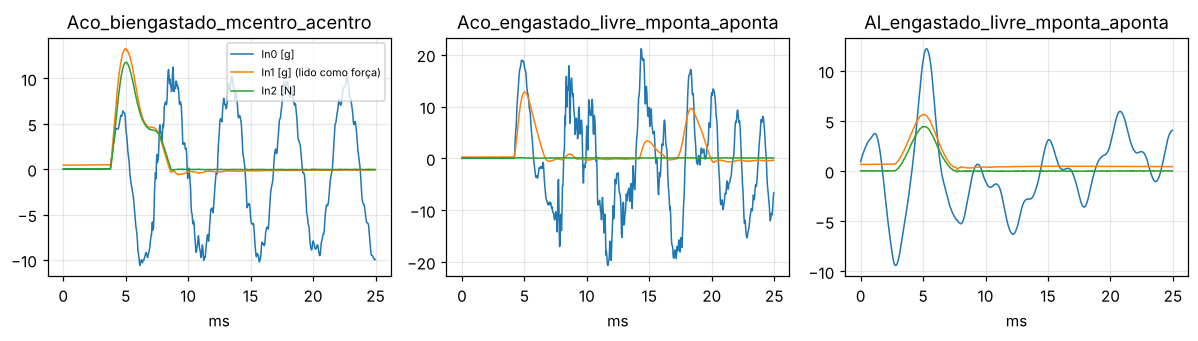

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2), sharey=False)
for ax, name in zip(axs, ["Aco_biengastado_mcentro_acentro.csv", "Aco_engastado_livre_mponta_aponta.csv",
                          "Al_engastado_livre_mponta_aponta.csv"]):
    d = ref.read_ni_csv(lh.RAW_DIR / "exp_5" / name)
    fs = d["fs"]
    i0 = int(np.nanargmax(np.abs(d["ch"][1] - np.nanmedian(d["ch"][1][:500]))))
    sl = slice(max(i0 - int(0.005 * fs), 0), i0 + int(0.02 * fs))
    t = (np.arange(sl.stop - sl.start)) / fs * 1e3
    for k, lab in enumerate(["In0 [g]", "In1 [g] (lido como força)", "In2 [N]"]):
        ax.plot(t, d["ch"][k][sl], lw=1, label=lab)
    ax.set(title=name.replace(".csv", ""), xlabel="ms"); ax.grid(alpha=0.3)
axs[0].legend(fontsize=7)
fig.tight_layout()

**Resultado: inconclusivo — reformulado.** Os dados não permitem fechar o mapeamento:
* Nos **dois ensaios de aço em engaste-livre** (incluindo o caso da Tabela 5 do TCC) o
  **Input 2 [N] só tem ruído** (pico ≤ 0,08 N, igual ao ruído de fundo) e o pulso de
  impacto está no **Input 1**. Nesses arquivos, ler o Input 1 como força — o que o legado
  faz — é provavelmente o certo, e o rótulo "g" é que estaria errado.
* Nos outros 10 arquivos (biengastados e acrílico/alumínio em engaste-livre, inclusive o
  caso do `main.py`), **Input 1 e Input 2 mostram pulsos quase idênticos** (mesmo instante,
  mesma largura, amplitudes 7–30 % diferentes). Ou o martelo foi gravado em dois canais,
  ou o Input 1 é um acelerômetro no ponto de impacto.
* Se o martelo estava no Input 1 com a sensibilidade de acelerômetro (100 mV/g) configurada,
  o valor em "g" não é newton: a **escala de força** desses arquivos é desconhecida, e com
  ela a amplitude absoluta das FRFs da 1ª campanha.

→ É preciso o **registro do ensaio** de jan/2023 (o que estava ligado em cada entrada do
NI 9234 e com que sensibilidade). Até lá, a 1ª campanha não é usada para nada que
dependa de amplitude (regra §13 do prompt master).

## 2. C5 — unidades e fatores de escala do legado
Pelo cabeçalho, a 2ª campanha está em `g, g, N`. A acelerância correta é
A = (a_g · g₀) / F [m/s²/N]. O legado calcula `2/N · |FFT(a)/FFT(F)|` com `a` em g
(1ª campanha) ou `a·9,81` (2ª campanha), e depois divide a FRF numérica por 9810².

In [4]:
f, H, coh = ref.simple_h1(*[np.array([x]) for x in (
    ref.read_ni_csv(lh.RAW_DIR / "AÇO" / "LL_ACO_02.csv")["ch"][2],
    ref.read_ni_csv(lh.RAW_DIR / "AÇO" / "LL_ACO_02.csv")["ch"][0] * ref.G0)], 25600.0)
N = len(ref.read_ni_csv(lh.RAW_DIR / "AÇO" / "LL_ACO_02.csv")["t"])
print(f"Fator 2/N do legado para um registro de {N} amostras: {2 / N:.2e}")
print("Numa razão FFT(a)/FFT(F) as normalizações do numerador e do denominador se cancelam;")
print("aplicar 2/N uma vez escala a FRF por esse fator (≈ 1/64 000 aqui).")
print(f"Ex.: aço, 1º pico: |A| correto ≈ {np.abs(H[(f > 150) & (f < 165)]).max():.0f} m/s²/N; "
      f"no legado apareceria como ≈ {np.abs(H[(f > 150) & (f < 165)]).max() * 2 / N:.3f}")
print("Outros fatores 'mágicos' no legado: amplitude *= 9.81 (main.py, força tratada como g),",
      "a_num/9810 e |A_num|/9810² nos plots — nenhum vem de uma conversão de unidade nomeada.")

Fator 2/N do legado para um registro de 128000 amostras: 1.56e-05
Numa razão FFT(a)/FFT(F) as normalizações do numerador e do denominador se cancelam;
aplicar 2/N uma vez escala a FRF por esse fator (≈ 1/64 000 aqui).
Ex.: aço, 1º pico: |A| correto ≈ 3258 m/s²/N; no legado apareceria como ≈ 0.051
Outros fatores 'mágicos' no legado: amplitude *= 9.81 (main.py, força tratada como g), a_num/9810 e |A_num|/9810² nos plots — nenhum vem de uma conversão de unidade nomeada.


**Confirmado (C5).** A escala da FRF experimental do legado está errada por um fator 2/N
(~10⁻⁵), e os fatores 9,81, 9810 e 9810² foram ajustes manuais para sobrepor as curvas.
Como RVAC/TSAC são invariantes à escala (notebook 02), o erro nunca apareceu.

## 3. C6 — filtro Butterworth aplicado à magnitude da FRF
Teste controlado: FRF analítica de 1 GL (acelerância, ζ conhecido) amostrada com o Δf da
1ª campanha (0,25 Hz), filtrada exatamente como no legado (`butter(N=7, Wn=0.5)` +
`filtfilt` sobre a **magnitude**, no eixo da frequência). Também com `Wn = 0,02`, valor que
o TCC (Algoritmo 4) diz ter usado para o alumínio.

 ζ verdadeiro  ζ meia-potência sem filtro  ζ c/ filtro Wn=0.5  viés Wn=0.5 [%]  ζ c/ filtro Wn=0.02  viés Wn=0.02 [%]
        0.001                     0.00101             0.00203            102.7              0.03938            3837.7
        0.005                     0.00501             0.00502              0.4              0.04185             737.0
        0.020                     0.02006             0.02006              0.3              0.04880             144.0


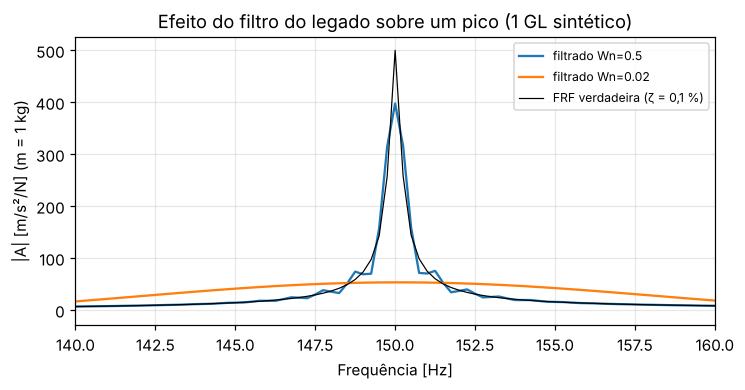

In [5]:
df = 0.25
fgrid = np.arange(0, 500, df)
rows = []
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for zeta in (0.001, 0.005, 0.02):
    mag = np.abs(ref.sdof_accelerance(fgrid, 150.0, zeta))
    z0, _ = ref.half_power_zeta(fgrid, mag, 100, 200)
    out = {"ζ verdadeiro": zeta, "ζ meia-potência sem filtro": round(z0, 5)}
    for Wn in (0.5, 0.02):
        b, a = butter(N=7, Wn=Wn, btype="lowpass")
        filt = filtfilt(b, a, mag)
        zf, fpk = ref.half_power_zeta(fgrid, filt, 100, 200)
        out[f"ζ c/ filtro Wn={Wn}"] = round(zf, 5)
        out[f"viés Wn={Wn} [%]"] = round(100 * (zf / zeta - 1), 1)
        if zeta == 0.001:
            ax.plot(fgrid, filt, label=f"filtrado Wn={Wn}")
    if zeta == 0.001:
        ax.plot(fgrid, mag, "k", lw=0.8, label="FRF verdadeira (ζ = 0,1 %)")
    rows.append(out)
ax.set(xlim=(140, 160), xlabel="Frequência [Hz]", ylabel="|A| [m/s²/N] (m = 1 kg)",
       title="Efeito do filtro do legado sobre um pico (1 GL sintético)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
with pd.option_context("display.width", 200):
    print(pd.DataFrame(rows).to_string(index=False))

**Confirmado (C6).** O filtro alarga e achata os picos: o ζ estimado sai **viesado para
cima** — pouco para picos largos, muito para picos estreitos (exatamente os metais de
baixo amortecimento). Com `Wn = 0,02` o pico praticamente desaparece. O código usa 0,5
para todos os materiais; o TCC diz 0,02 para o alumínio (divergência registrada). Filtrar
a magnitude da FRF não é uma operação válida de processamento de sinais: o ruído deve ser
tratado com médias de espectros, janelas e coerência (Fase 2).

## 4. I7 — `frf_direta` usa ω = f/(2π)
`frf_direta` (não usada pelos scripts, mas presente na biblioteca) avalia a FRF em
`omega = freq/2/np.pi`. A ressonância aparece então em f = 2π·ωₙ = 4π²·fₙ ≈ 39,5·fₙ.

In [6]:
f_dir, _, _, a_dir = B.frf_direta("engastado_livre", "aluminio", 1.0, 1, 2000, 4000, 1, 1e-4, 1e-3, 1e-7)
pk = f_dir[np.argmax(np.abs(a_dir))]
print(f"1º modo do Al em balanço (modelo legado): 35,6 Hz → frf_direta põe o pico em {pk:.0f} Hz "
      f"(= {pk / 35.577:.1f} × 35,6 Hz; 4π² = {4 * np.pi**2:.1f})")

1º modo do Al em balanço (modelo legado): 35,6 Hz → frf_direta põe o pico em 1405 Hz (= 39.5 × 35,6 Hz; 4π² = 39.5)


**Confirmado (I7).**

## 5. I8 — fase pela metade

In [7]:
print("np.angle(-1) * 180/2/π  =", np.angle(-1 + 0j) * 180 / 2 / np.pi, "graus (legado) — o correto é 180")

np.angle(-1) * 180/2/π  = 90.0 graus (legado) — o correto é 180


**Confirmado (I8).** Todas as fases do legado (`pos_experimental`, `pos_experimental_livre_livre`)
estão divididas por 2. Em `frf_tempo` a conversão é aplicada ainda **dentro** do
`np.angle(...)`, o que também está errado.

## 6. I10 — média de magnitudes e de fases (livre-livre)
Comparação, para o aço livre-livre, entre a "FRF média" do legado (média de |H| e de
fase de 16 FFTs cortadas pelo trigger da aceleração) e um H1 simples (média de auto e
cross-espectros, registros alinhados pela força). Ambos com 3,5 s de registro.

1º modo: legado f = 157.72 Hz, ζ(meia-potência) = 0.00148 | H1 f = 157.50 Hz, ζ = 0.00129


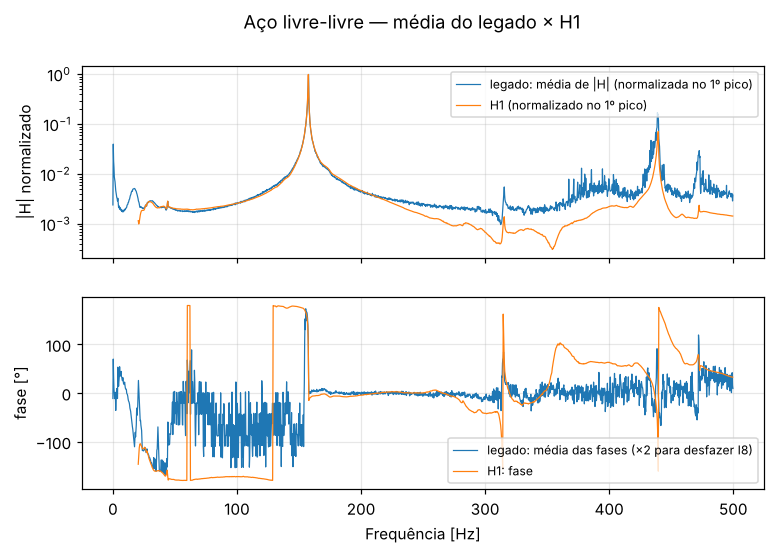

In [8]:
with lh.legacy_workdir():
    out = B.pos_experimental_livre_livre("aco", 500, 3.5, 16)
f_leg, ph_leg, amp_leg = out[8], out[2], out[5]
F, X = [], []
for i in range(1, 17):
    d = ref.read_ni_csv(lh.RAW_DIR / "AÇO" / f"LL_ACO_{i:02d}.csv")
    i0 = ref.force_onset(d["ch"][2], d["fs"]) - int(0.005 * d["fs"])
    n = int(2.4 * d["fs"])
    F.append(d["ch"][2][i0:i0 + n]); X.append(d["ch"][0][i0:i0 + n] * ref.G0)
fh, Hh, coh = ref.simple_h1(np.array(F), np.array(X), 25600.0)
sel = (fh > 20) & (fh < 500)
fig, axs = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axs[0].semilogy(f_leg, amp_leg / amp_leg[(f_leg > 150) & (f_leg < 165)].max(), lw=0.8, label="legado: média de |H| (normalizada no 1º pico)")
axs[0].semilogy(fh[sel], np.abs(Hh[sel]) / np.abs(Hh[(fh > 150) & (fh < 165)]).max(), lw=0.8, label="H1 (normalizado no 1º pico)")
axs[0].legend(fontsize=8); axs[0].grid(alpha=0.3); axs[0].set_ylabel("|H| normalizado")
axs[1].plot(f_leg, ph_leg * 2, lw=0.8, label="legado: média das fases (×2 para desfazer I8)")
axs[1].plot(fh[sel], np.degrees(np.angle(Hh[sel])), lw=0.8, label="H1: fase")
axs[1].set(xlabel="Frequência [Hz]", ylabel="fase [°]"); axs[1].legend(fontsize=8); axs[1].grid(alpha=0.3)
fig.suptitle("Aço livre-livre — média do legado × H1")
z_leg, f_pk_leg = ref.half_power_zeta(f_leg, amp_leg, 140, 175)
z_h1, f_pk_h1 = ref.half_power_zeta(fh, np.abs(Hh), 140, 175)
print(f"1º modo: legado f = {f_pk_leg:.2f} Hz, ζ(meia-potência) = {z_leg:.5f} | H1 f = {f_pk_h1:.2f} Hz, ζ = {z_h1:.5f}")

**Confirmado (I10).** A média de fases de ±180° produz curvas sem sentido físico (fases
"médias" que nenhum ensaio teve), e a média de magnitudes de registros desalinhados
(triggers diferentes, notebook 01) distorce os picos. A largura do pico — e portanto o ζ
por meia-potência — muda entre as duas abordagens. O estimador correto (H1/H2, com
coerência) é tarefa da Fase 2. *(O ζ acima é só ilustração; com Δf de 0,29–0,42 Hz e
janela retangular, nenhum dos dois é uma estimativa confiável de ζ ~ 10⁻³.)*

## 7. I11 — trigger e impactos múltiplos
Contagem de pulsos de força (> 10 % do pico, separados por ≥ 10 ms) em cada arquivo.

In [9]:
rows = []
for folder, pat in [("AÇO", "LL_ACO_{:02d}.csv"), ("Al", "Al_livre_livre_{}.csv"), ("ACRILICO", "LL_ACRILICO_{:02d}.csv")]:
    counts = []
    for i in range(1, 17):
        d = ref.read_ni_csv(lh.RAW_DIR / folder / pat.format(i))
        counts.append(ref.count_impacts(d["ch"][2], d["fs"])[0])
    rows.append({"conjunto": folder, "ensaios": 16, "com 1 impacto": counts.count(1),
                 "com ≥ 2 impactos": sum(c >= 2 for c in counts), "pulsos por ensaio": counts})
print(pd.DataFrame(rows).to_string(index=False))

conjunto  ensaios  com 1 impacto  com ≥ 2 impactos                                pulsos por ensaio
     AÇO       16             15                 1 [1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1]
      Al       16             14                 2 [1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1]
ACRILICO       16              1                15 [1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


**Confirmado (I11).** O legado não detecta impactos múltiplos, não usa pré-trigger nem
janelas, e dispara pelo canal de aceleração (no aço, até 2 s antes do golpe — notebook
01). A tabela mostra quantos ensaios têm mais de um pulso de força; o critério de
rejeição é a decisão D1.2 da Fase 1. Destaque: **15 dos 16 ensaios de acrílico têm dois
impactos** (rebote do martelo), contra 1–2 de 16 nos metais. *(Contagem com limiar de 10 %
do pico: rebotes menores não aparecem; o detector definitivo é da Fase 2.)*

## Resumo da etapa
| Item | Status | Evidência |
|---|---|---|
| C9 | **inconclusivo (reformulado)** | aço engaste-livre: Input 2 [N] só ruído, pulso no Input 1; demais 10 arquivos: pulso quase idêntico nos dois. Precisa do registro do ensaio |
| C5 | **confirmado** | fator 2/N (~10⁻⁵) na FRF; 9,81/9810/9810² manuais |
| C6 | **confirmado** | filtro na magnitude viesa ζ para cima (muito para picos estreitos); Wn 0,5 no código × 0,02 no TCC |
| I7 | **confirmado** | pico de `frf_direta` em 39,5 × fₙ |
| I8 | **confirmado** | fase ×½ |
| I10 | **confirmado** | média de fases e de magnitudes desalinhadas |
| I11 | **confirmado** | trigger pela aceleração; duplo impacto em 15/16 ensaios de acrílico, 2/16 Al, 1/16 aço |